In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("data/fig2_source_data.csv")
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={
    "Fig2a_WetlandDensity": "wetland_density",
    "Fig2b_PercentNRemoval": "pct_n_removal",
    "Fig2c_NSurplus": "n_surplus",
    "Fig2d_EstNRemoval": "est_n_removal",
})
df["region"] = df["HUC8"] // 1_000_000

quant = ["wetland_density", "pct_n_removal", "n_surplus", "est_n_removal"]
Xz = StandardScaler().fit_transform(df[quant]) 

pca = PCA()
scores = pca.fit_transform(Xz)
evr = pca.explained_variance_ratio_
print(evr.round(3), evr.cumsum().round(3))

[0.573 0.339 0.059 0.029] [0.573 0.912 0.971 1.   ]


Best k by silhouette: 3


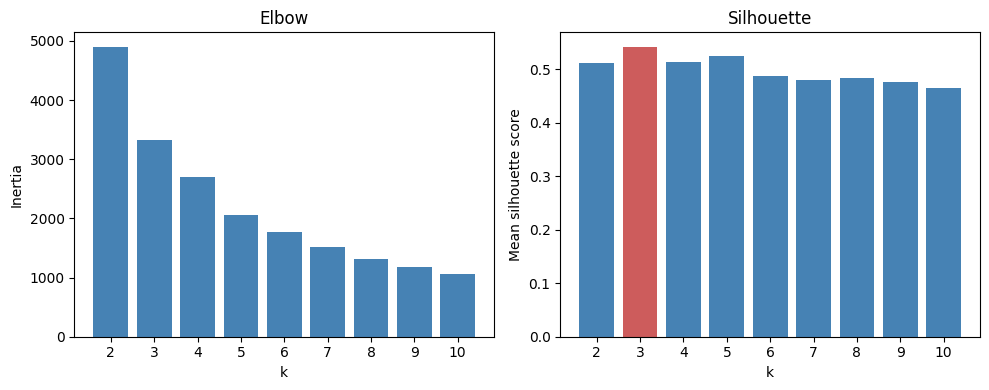

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xz)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xz, km.labels_))

best_k = ks[int(np.argmax(sil))]
print("Best k by silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(ks, inertia, color="steelblue")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow")
axes[1].bar(ks, sil, color=["indianred" if k == best_k else "steelblue" for k in ks])
axes[1].set_xlabel("k"); axes[1].set_ylabel("Mean silhouette score"); axes[1].set_title("Silhouette")
for ax in axes:
    ax.set_xticks(ks)
fig.tight_layout()
fig.savefig("figures/kmeans_k_selection.png", dpi=300)
plt.show()

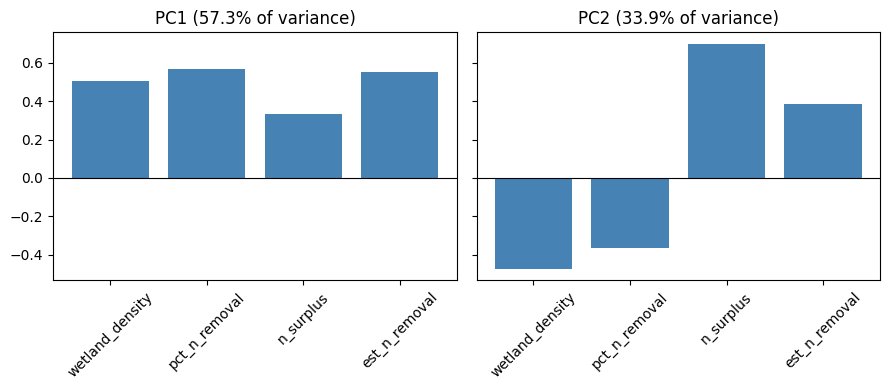

In [5]:
loadings = pd.DataFrame(pca.components_.T, index=quant,
                        columns=[f"PC{i+1}" for i in range(4)])
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for i, ax in enumerate(axes):
    pc = f"PC{i+1}"
    ax.bar(loadings.index, loadings[pc], color="steelblue")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{pc} ({evr[i]*100:.1f}% of variance)")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig("figures/pca_loadings_bar.png", dpi=300)
plt.show()

In [7]:
K = 3
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xz)
df["cluster"] = km.labels_

print(df["cluster"].value_counts().sort_index())
df.groupby("cluster")[quant].mean().round(2)

cluster
0     406
1    1361
2     331
Name: count, dtype: int64


,wetland_density,pct_n_removal,n_surplus,est_n_removal
cluster,,,,
0,0.22,0.43,9.69,2.05
1,0.03,0.11,8.63,0.50
2,0.08,0.26,42.97,4.84


In [8]:
groups = {1: "Northeast", 2: "Northeast",
          3: "Southeast", 6: "Southeast",
          4: "Midwest", 5: "Midwest", 7: "Midwest", 9: "Midwest",
          8: "South-Central", 10: "South-Central", 11: "South-Central", 12: "South-Central",
          13: "Southwest", 14: "Southwest", 15: "Southwest", 16: "Southwest",
          17: "Pacific", 18: "Pacific"}
df["region_group"] = df["region"].map(groups)
df["region_group"].isna().sum()

0

In [9]:
pd.crosstab(df["region_group"], df["cluster"])

cluster,0,1,2
region_group,,,
Midwest,114,127,167
Northeast,59,82,5
Pacific,17,297,32
South-Central,74,497,106
Southeast,141,75,19
Southwest,1,283,2
